## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [2]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [3]:
crosstab["proportion"] = crosstab[True] / (crosstab[True] + crosstab[False])
crosstab

isBestSeller,False,True,proportion
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [4]:
crosstab_sorted = crosstab.sort_values('proportion', ascending=False)
crosstab_sorted

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


Yes, Grocery, Smart Home Security & Lighting and Health & Personal Care are more prevalent but the proportion is only 5.7% each

In [5]:
from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab)

chi2_statistic, chi2_p_value

(np.float64(36684.23786636857), np.float64(0.0))

The null hypothesis of the Chi-square test is that the two categorical variables are independent. Given the extremely low ( p )-value, we reject the null hypothesis. This implies that there's a significant association between Category and isbestseller

In [6]:
from scipy.stats.contingency import association
crosstab_clean = crosstab.drop(columns=['proportion'])
association(crosstab_clean, method="cramer")

0.1222829439760564

- Interpretation: Cramer's V ranges from 0 to 1, where **0 indicates no association, and 1 represents a perfect association between the variables**
- The Cramér's V value of 0.122 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

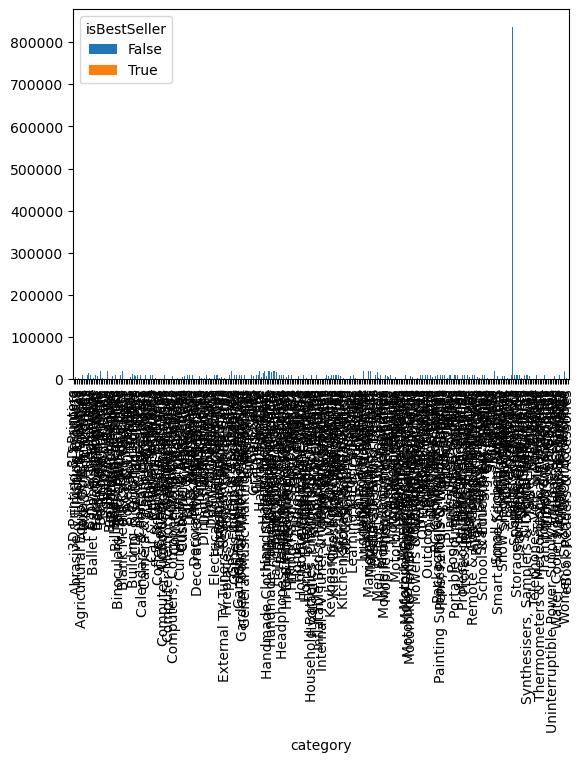

In [8]:
crosstab_clean.plot(kind="bar", stacked=True);

### As we can since, since there are 296 this is totally unreadable, instead, we could see the top 10: 

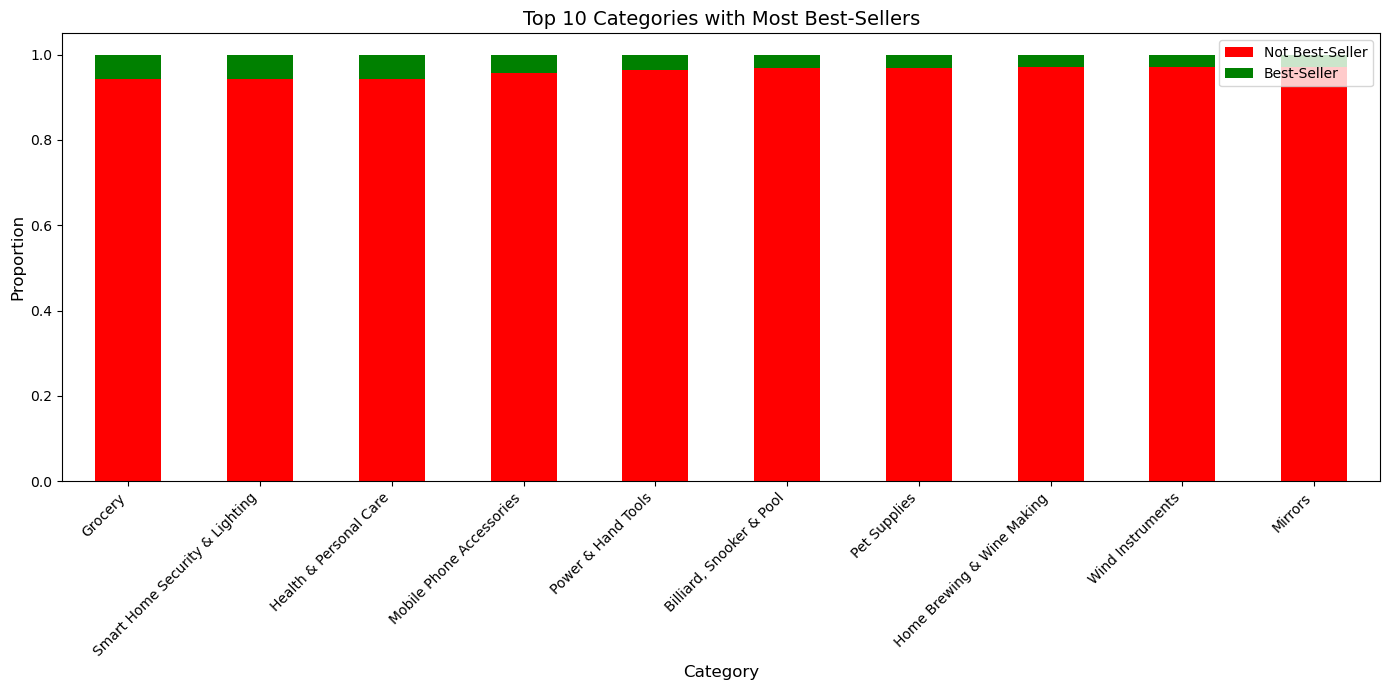

In [11]:
top10 = crosstab_clean.div(crosstab_clean.sum(axis=1), axis=0)
top10 = top10.sort_values(True, ascending=False).head(10)
top10.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    color=["Red", "Green"]
)
plt.title("Top 10 Categories with Most Best-Sellers", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.legend(["Not Best-Seller", "Best-Seller"], loc="upper right")
plt.tight_layout()
plt.show()


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


**Preliminary Step: Remove outliers in product prices.**

In [12]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [13]:
data_series = df["price"]
outliers = tukeys_test_outliers(data_series)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [14]:
df.shape

(2443651, 9)

In [15]:
df_clean = df[~df.index.isin(outliers.index)]

print(f"Original rows: {len(df)}")
print(f"Rows without outliers: {len(df_clean)}")

Original rows: 2443651
Rows without outliers: 2115963


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

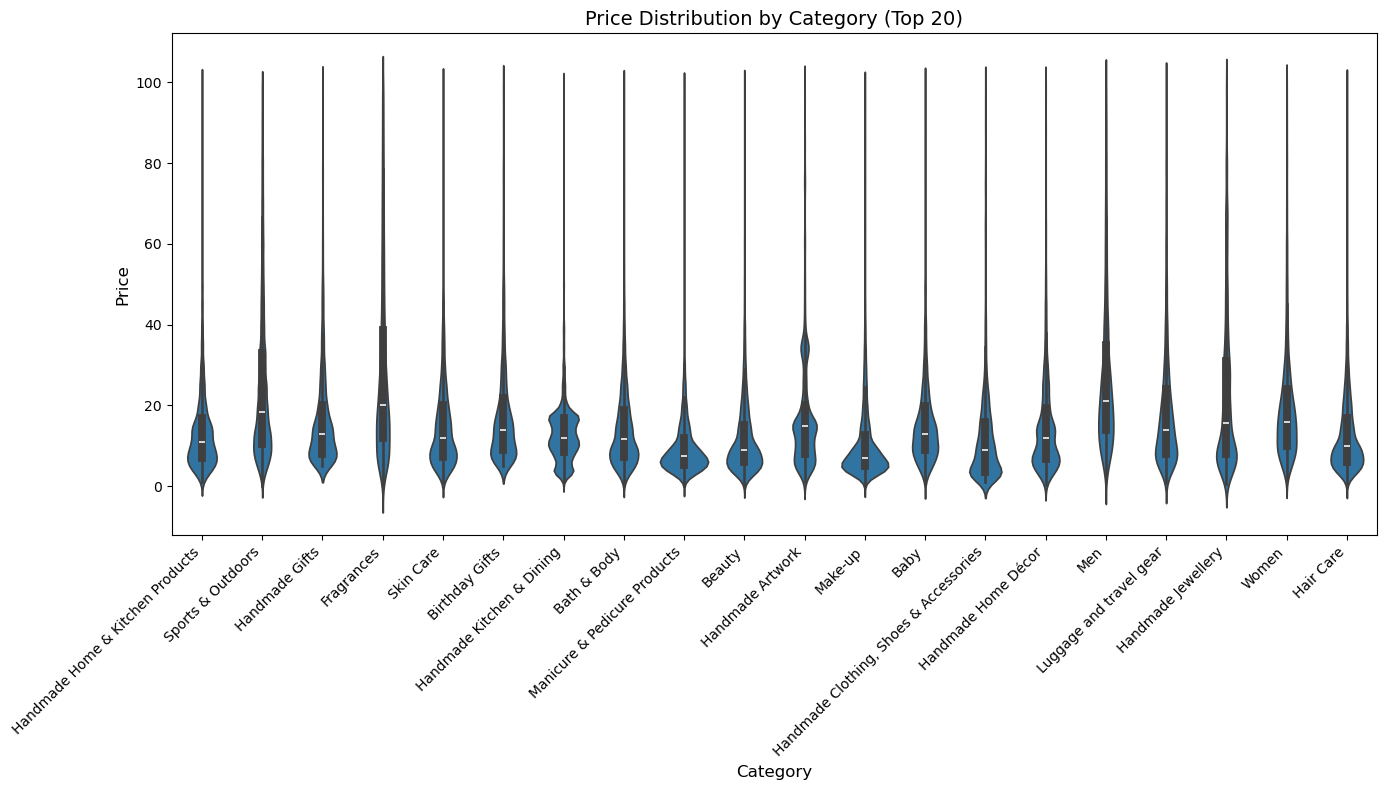

In [19]:
import seaborn as sns
top20_categories = df_clean["category"].value_counts().head(20).index  # Index returns the name, we are interested in the name not the value!
df_top20 = df_clean[df_clean["category"].isin(top20_categories)]
plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top20, x="category", y="price")
plt.title("Price Distribution by Category (Top 20)", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
median_price_by_category = df_clean.groupby("category")["price"].median().sort_values(ascending=False)
print(median_price_by_category.head(5))
print("")
print("Desktop PCs has the higher median")

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

Desktop PCs has the higher median


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

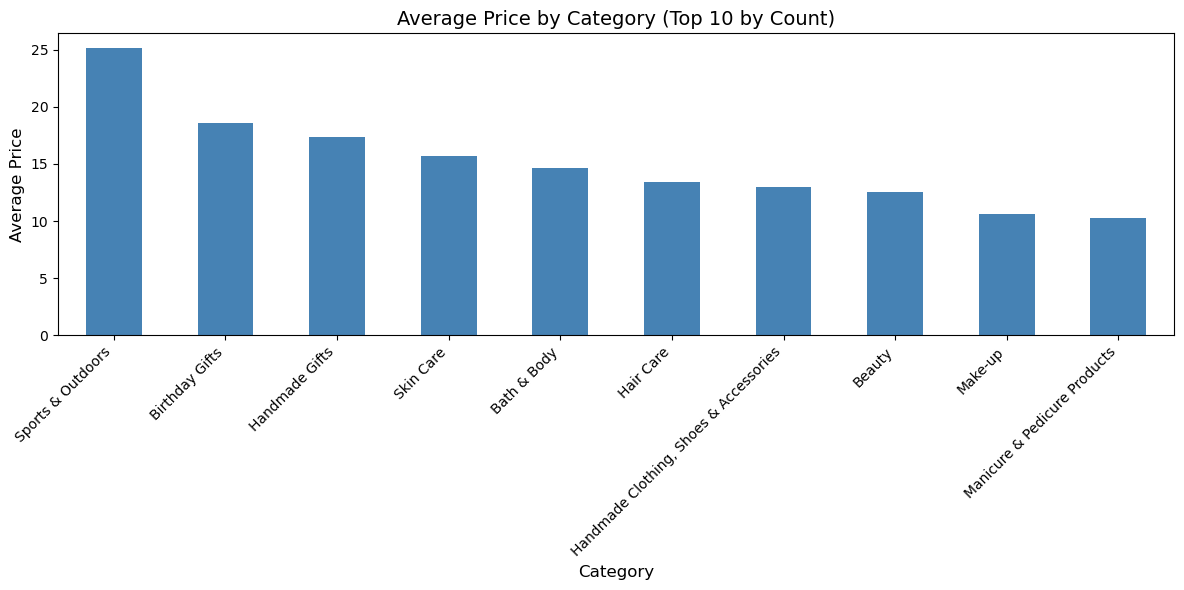

In [23]:
top10_categories = df_clean["category"].value_counts().head(10).index

df_top10 = df_clean[df_clean["category"].isin(top10_categories)]
avg_price = df_top10.groupby("category")["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_price.plot(kind="bar", color="steelblue")

plt.title("Average Price by Category (Top 10 by Count)", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Average Price", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



In [25]:
median_price_by_category = df_clean.groupby("category")["price"].mean().sort_values(ascending=False)
print(median_price_by_category.head(5))
print("")
print("Motherboards has the highest mean")

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

Motherboards has the highest mean


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


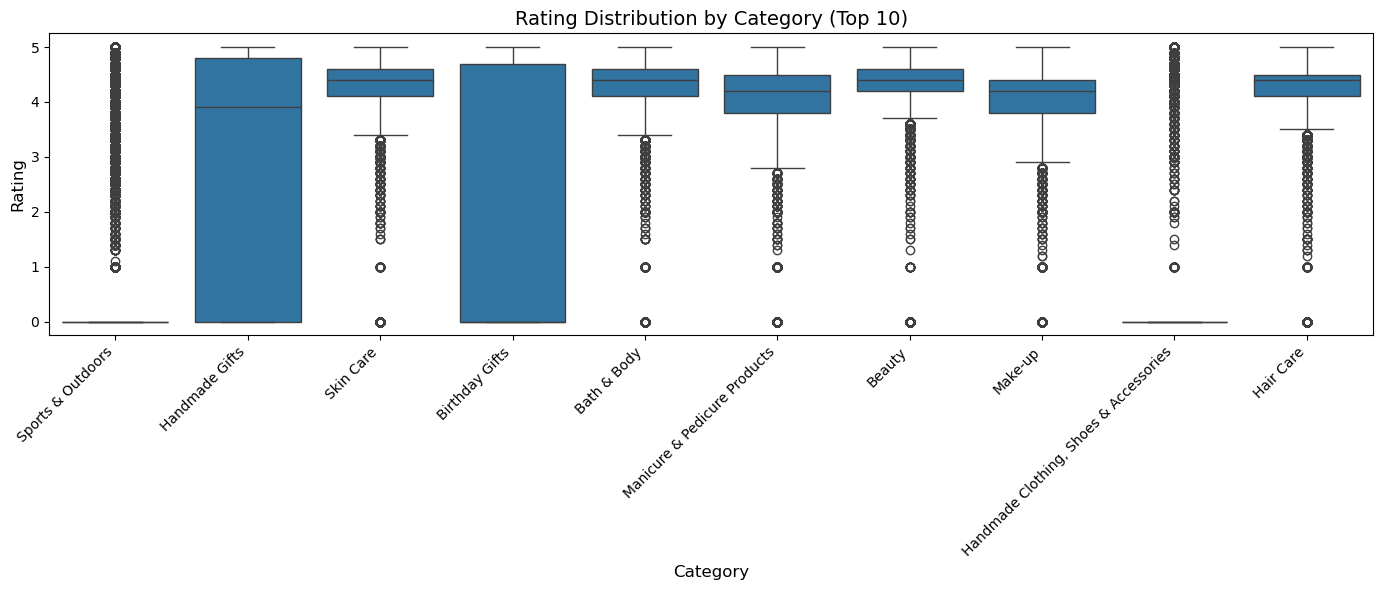

In [26]:
top10_categories = df_clean["category"].value_counts().head(10).index
df_top10 = df_clean[df_clean["category"].isin(top10_categories)]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top10, x="category", y="stars")

plt.title("Rating Distribution by Category (Top 10)", fontsize=14)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Rating", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [28]:
median_price_by_category = df_clean.groupby("category")["stars"].median().sort_values(ascending=False)
print(median_price_by_category.head(5))
print("")
print("Computer Memory tends to have the highest median")

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

Computer Memory tends to have the highest median


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

In [32]:
correlation = df_clean["price"].corr(df_clean["stars"])
print(f"Correlation coefficient: {correlation:.4f}")
print("")
print("The correlation is close to zero, so the price doesn't affect the rating significantly, expensive doesn't mean good and cheap bad")

Correlation coefficient: -0.0777

The correlation is close to zero, so the price doesn't affect the rating significantly, expensive doesn't mean good and cheap bad


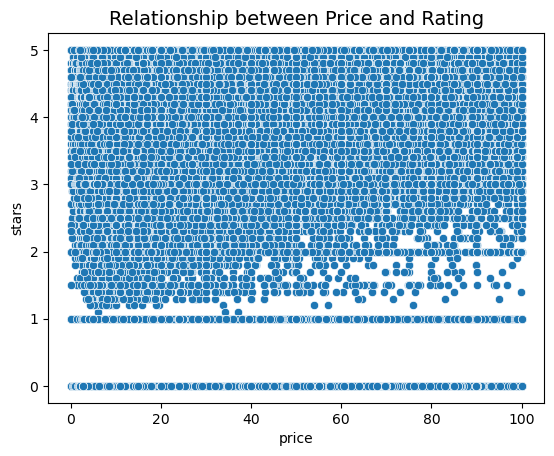

In [41]:
sns.scatterplot(data=df_clean, x="price", y="stars");
plt.title("Relationship between Price and Rating", fontsize=14)
plt.show()

Since the sample is so big we can't really draw exact conclutions, but it seems very concentrated in 2+, 1 and 0. In other words, there is no tendence
up or down, which means there is no relationship between price and rating

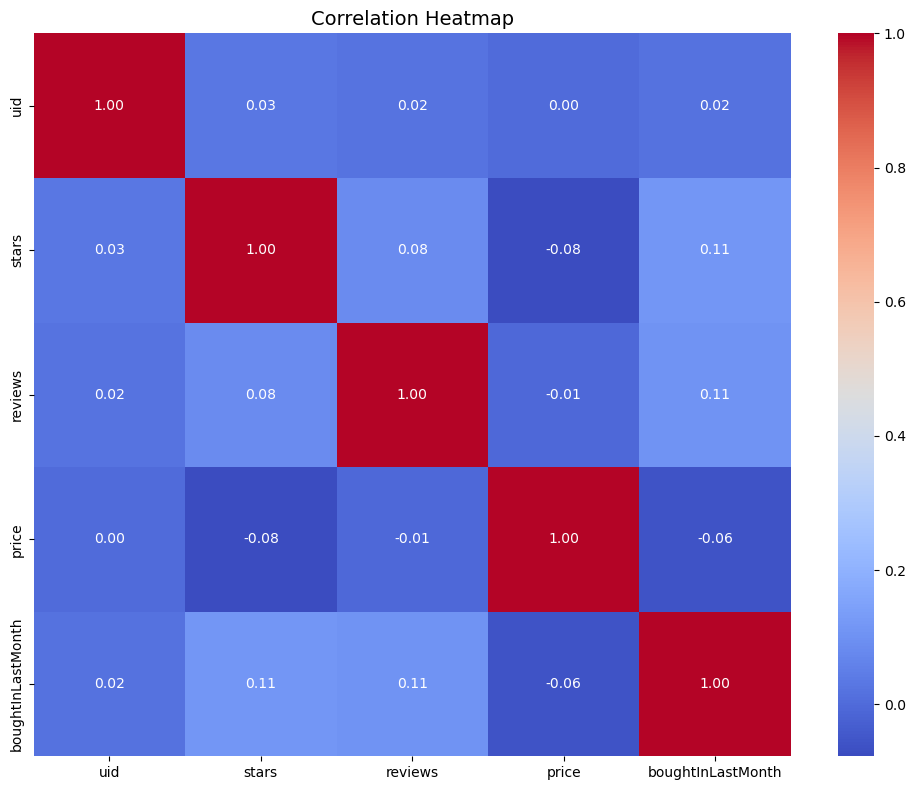

In [42]:
correlation_matrix = df_clean.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()


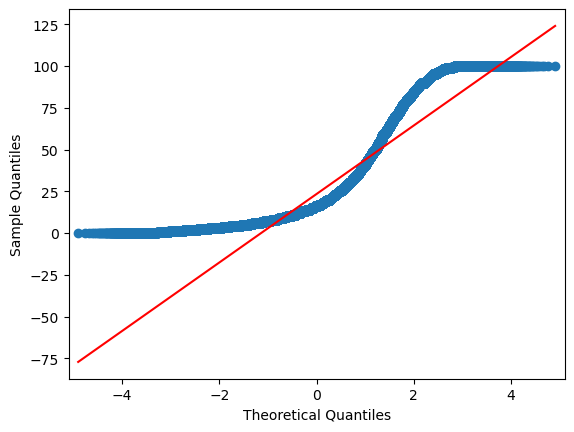

In [44]:
import statsmodels.api as sm

sm.qqplot(df_clean["price"], line='s');

# **Bonus** 

Do the same analysis without taking out the outliers. What are your insights?

In [47]:
correlation = df["price"].corr(df["stars"])
print(f"Correlation coefficient: {correlation:.4f}")


Correlation coefficient: -0.1249


The correlation is still close to zero, (though, of course higher in this case due to the outliers) the interpretation is the same: the price doesn't affect the rating significantly, expensive doesn't mean good and cheap bad

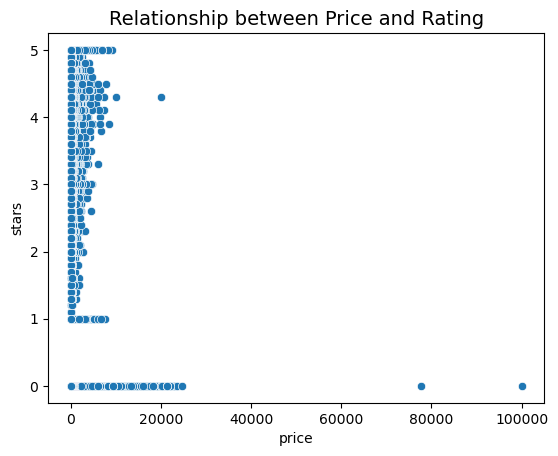

In [48]:
sns.scatterplot(data=df, x="price", y="stars");
plt.title("Relationship between Price and Rating", fontsize=14)
plt.show()

Here, due to the outliers it doesn't look like a perfect square, but still, most of the ratings are concentrated in the lower prices, is the same but harder to interpret visually

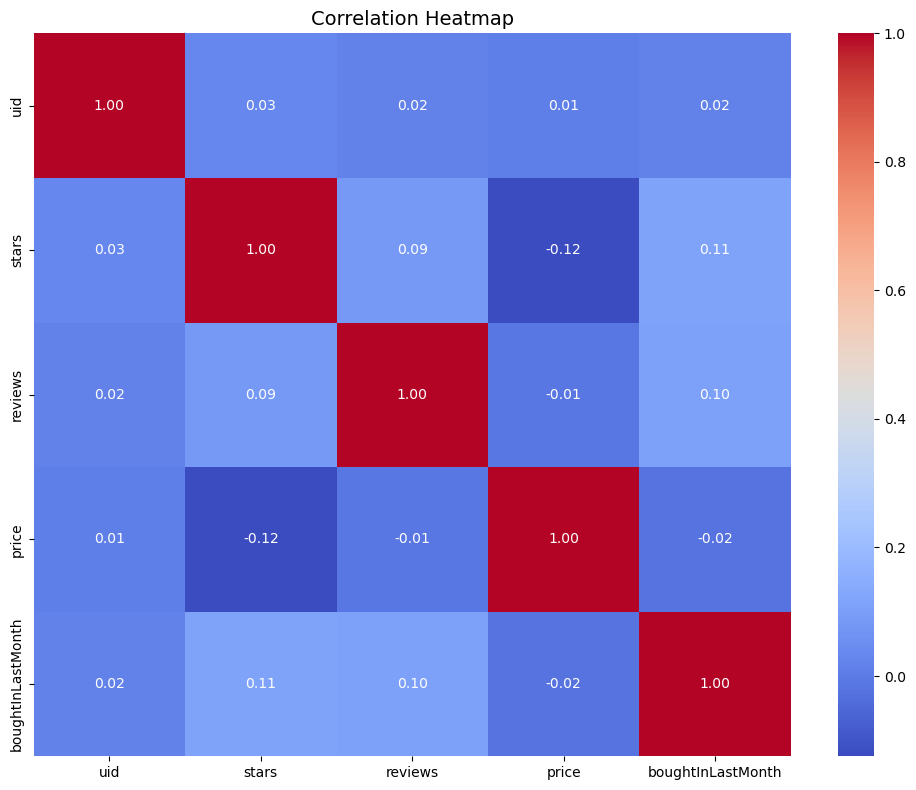

In [49]:
correlation_matrix = df.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

The heatmap varelly changed, that is because there is a very very low correlation

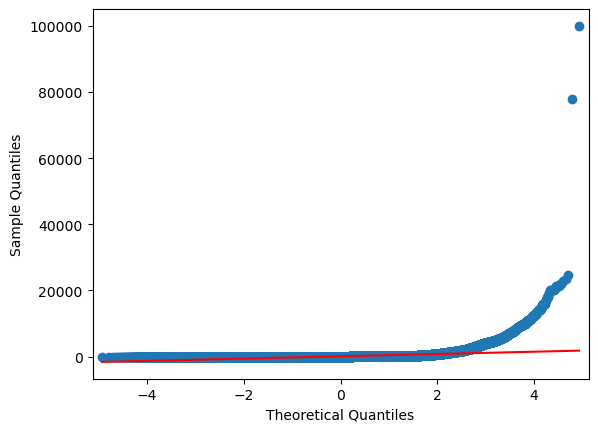

In [50]:
sm.qqplot(df["price"], line='s');

On the other hand, here we are not talking about correlation but the impact of the variable itself. Since we kept the outliers we can see how much noise they can cause 